# Code 5: Quantum neural network for MNIST classification

This notebook goes with [Lecture 6](../content/lectures/lecture6.md), and uses the parameter-shift rule from [Lecture 5](../content/lectures/lecture5.md). We train a parametrised quantum circuit to tell handwritten **0**s from **1**s.

The plan:
1. load MNIST and shrink each image down to **9 pixels**, one per qubit,
2. **encode** each pixel value $x_i\in[0,1]$ as a rotation $R_Y(\pi x_i)$ on qubit $i$,
3. apply a trainable circuit, then measure $\langle Z_0\rangle\in[-1,1]$ as the model's prediction,
4. train with the **hinge loss**, using exact gradients from the **parameter-shift rule** and the Adam optimiser.

```{note}
Training takes a few minutes on a laptop. We use a few hundred training images, not the full 12 000. Simulating quantum circuits is expensive, and that is exactly why we would like quantum hardware! For bigger runs (more images, qubits or layers), use the HPC. See [Setting up Python and Qiskit](../content/outline/pythonEnvironment.md).
```

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer.primitives import EstimatorV2 as AerEstimator

rng = np.random.default_rng(4041)

## Load and reduce the data

`torchvision` downloads MNIST (about 50 MB) the first time into `data/`. We keep only the digits 0 and 1, scaled to $[0,1]$.

In [2]:
import contextlib, io

def load_mnist(train):
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):   # hide download progress
        ds = torchvision.datasets.MNIST("data", train=train, download=True)
    return ds.data.numpy() / 255.0, ds.targets.numpy()

x_train_full, y_train_full = load_mnist(train=True)
x_test_full, y_test_full = load_mnist(train=False)
print("original training / test images:", len(x_train_full), len(x_test_full))

def filter_digits(x, y, digits=(0, 1)):
    keep = np.isin(y, digits)
    return x[keep], y[keep]

x_train, y_train = filter_digits(x_train_full, y_train_full)
x_test, y_test = filter_digits(x_test_full, y_test_full)
print("0/1 training / test images:   ", len(x_train), len(x_test))

original training / test images: 60000 10000
0/1 training / test images:    12665 2115


Nine qubits means nine numbers per image. We first shrink $28\times 28 \to 9\times 9$ (by averaging nearby pixels), then keep only the **central row**.

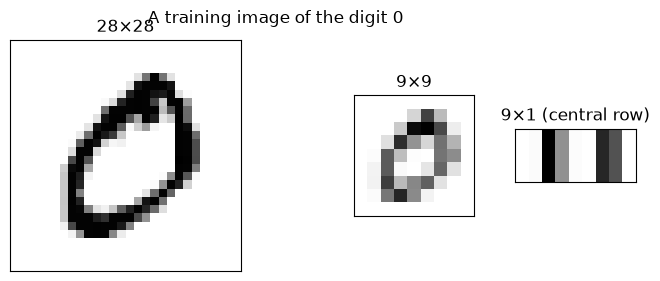

In [3]:
def shrink(x, size=9):
    t = torch.tensor(x, dtype=torch.float32)[:, None]                  # (N, 1, 28, 28)
    small = torch.nn.functional.interpolate(t, size=(size, size), mode="area")
    return small[:, 0].numpy()                                          # (N, 9, 9)

x_train_9x9, x_test_9x9 = shrink(x_train), shrink(x_test)
x_train_9, x_test_9 = x_train_9x9[:, 4, :], x_test_9x9[:, 4, :]       # central row: (N, 9)

fig, axes = plt.subplots(1, 3, figsize=(9, 3), gridspec_kw={"width_ratios": [28, 9, 9]})
axes[0].imshow(x_train[0], cmap="Greys");                axes[0].set_title("28×28")
axes[1].imshow(x_train_9x9[0], cmap="Greys");            axes[1].set_title("9×9")
axes[2].imshow(x_train_9[:1], cmap="Greys", aspect=4);   axes[2].set_title("9×1 (central row)")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(f"A training image of the digit {y_train[0]}")
plt.show()

For the hinge loss, labels must be $\pm 1$. We use $+1$ for a **0** and $-1$ for a **1**. We train on a random subset to keep things quick.

In [4]:
N_TRAIN, N_TEST = 400, 400

i_train = rng.choice(len(x_train_9), N_TRAIN, replace=False)
i_test = rng.choice(len(x_test_9), N_TEST, replace=False)
X_train, X_test = x_train_9[i_train], x_test_9[i_test]
Y_train = np.where(y_train[i_train] == 0, 1.0, -1.0)
Y_test = np.where(y_test[i_test] == 0, 1.0, -1.0)

## The quantum neural network

The circuit has an **encoding** layer, $R_Y(\pi x_i)$ on each qubit $i$, followed by `n_layers` trainable layers. Each layer applies a general single-qubit rotation $R_Z R_Y R_Z$ to qubit 0 and to qubit $i$, then a CNOT from $i$ to 0, for each of $i = 1,\dots,8$, and finishes with one more rotation on qubit 0. All the information is funnelled into qubit 0, which we measure.

trainable parameters: 51


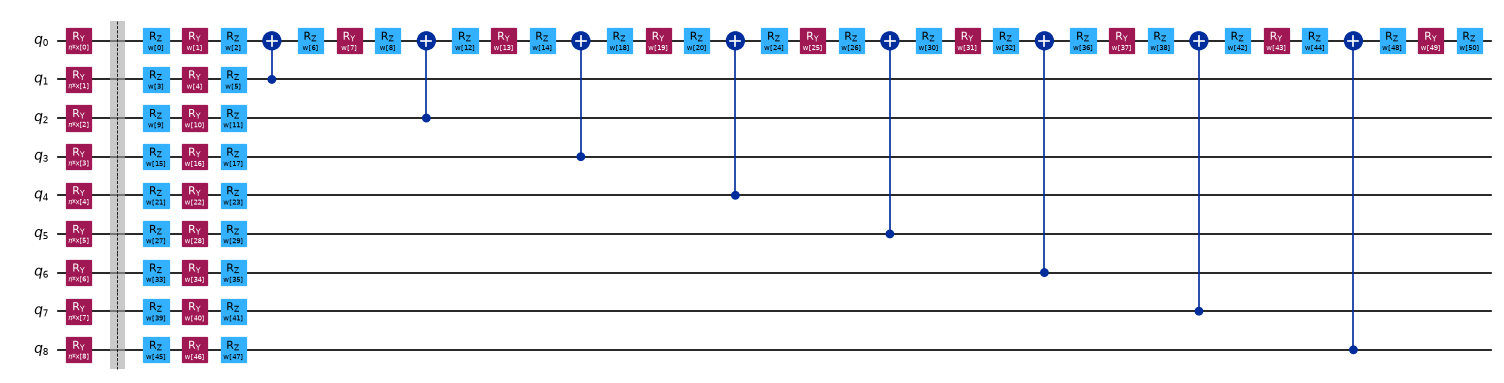

In [5]:
n_qubits = 9

def general_rotation(qc, w, qubit):
    qc.rz(w[0], qubit)
    qc.ry(w[1], qubit)
    qc.rz(w[2], qubit)

def make_qnn(n_layers):
    # Return (circuit, data parameters, weight parameters).
    x = ParameterVector("x", n_qubits)
    w = ParameterVector("w", n_layers * (2 * (n_qubits - 1) + 1) * 3)
    qc = QuantumCircuit(n_qubits)
    for i in range(n_qubits):
        qc.ry(np.pi * x[i], i)                    # encoding
    k = 0
    for _ in range(n_layers):
        qc.barrier()
        for i in range(1, n_qubits):
            general_rotation(qc, w[k:k + 3], 0); k += 3
            general_rotation(qc, w[k:k + 3], i); k += 3
            qc.cx(i, 0)
        general_rotation(qc, w[k:k + 3], 0); k += 3
    return qc, x, w

qc1, x_par, w_par = make_qnn(n_layers=1)
print("trainable parameters:", len(w_par))
qc1.draw("mpl", fold=40, scale=0.6)

## Predictions and the parameter-shift rule

Every trainable gate is a rotation $e^{-i\theta P/2}$ with $P$ a Pauli matrix. For these, the parameter-shift rule from Lecture 5 gives the **exact** derivative:

$$
\frac{\partial f}{\partial w_j} = \frac{f(w_j + \tfrac{\pi}{2}) - f(w_j - \tfrac{\pi}{2})}{2}.
$$

For $P$ weights and a batch of $B$ images, we need $B\,(2P+1)$ circuit evaluations: one unshifted, plus a $\pm$ shift for every weight. We hand all of them to the Estimator in a **single call**, as one array of parameter values. Doing this efficiently is what makes training feasible.

We use Qiskit Aer's fast simulator with `default_precision=0`, i.e. exact expectation values (no shot noise).

In [6]:
estimator = AerEstimator(options={"default_precision": 0.0})
Z0 = SparsePauliOp("I" * (n_qubits - 1) + "Z")          # Z on qubit 0 (rightmost)

def predict(qc, x_par, w_par, X, W):
    # Model outputs <Z0> for a batch of images X (B, 9) and weights W (P,).
    bindings = {tuple(x_par): X, tuple(w_par): np.broadcast_to(W, (len(X), len(W)))}
    return estimator.run([(qc, Z0, bindings)]).result()[0].data.evs

def predict_and_gradient(qc, x_par, w_par, X, W):
    # Outputs (B,) and parameter-shift gradients d<Z0>/dW (B, P).
    P = len(W)
    shifts = np.vstack([np.zeros(P), np.pi / 2 * np.eye(P), -np.pi / 2 * np.eye(P)])   # (2P+1, P)
    W_all = np.broadcast_to(W + shifts, (len(X), 2 * P + 1, P))                       # (B, 2P+1, P)
    X_all = np.broadcast_to(X[:, None, :], (len(X), 2 * P + 1, X.shape[1]))           # (B, 2P+1, 9)
    evs = estimator.run([(qc, Z0, {tuple(x_par): X_all, tuple(w_par): W_all})]).result()[0].data.evs
    f = evs[:, 0]
    grad = (evs[:, 1:P + 1] - evs[:, P + 1:]) / 2
    return f, grad

**Always check a gradient!** Here we compare the parameter-shift result with a small finite difference:

In [7]:
W_test = rng.uniform(0, 2 * np.pi, len(w_par))
f, g = predict_and_gradient(qc1, x_par, w_par, X_train[:2], W_test)
j, eps = 1, 1e-4                                   # w_1 is the R_Y on qubit 0 in the first block
e_j = np.zeros(len(W_test)); e_j[j] = eps
fd = (predict(qc1, x_par, w_par, X_train[:2], W_test + e_j) - predict(qc1, x_par, w_par, X_train[:2], W_test - e_j)) / (2 * eps)
print(f"parameter shift   dF/dw_{j}:", g[:, j].round(6))
print(f"finite difference dF/dw_{j}:", fd.round(6))

parameter shift   dF/dw_1: [0.049902 0.058396]
finite difference dF/dw_1: [0.049902 0.058396]


## Loss, accuracy and training

The hinge loss is $\mathcal{L} = \frac1B\sum_b \max(0,\, 1 - y_b f_b)$. By the chain rule,

$$
\frac{\partial\mathcal L}{\partial w_j} = \frac1B\sum_b \big(-y_b\big)\,[\,y_b f_b < 1\,]\,\frac{\partial f_b}{\partial w_j},
$$

where $[\cdot]$ is 1 if true and 0 otherwise. A prediction is correct if $f_b$ has the same sign as $y_b$. We update the weights with the **Adam** optimiser, written out in a few lines so nothing is hidden.

In [8]:
def hinge_loss(f, y):
    return np.mean(np.maximum(0, 1 - y * f))

def accuracy(f, y):
    return np.mean(np.sign(f) == y)

class Adam:
    def __init__(self, lr=0.1, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps = lr, beta1, beta2, eps
        self.m = self.v = None
        self.t = 0
    def step(self, W, grad):
        if self.m is None:
            self.m, self.v = np.zeros_like(W), np.zeros_like(W)
        self.t += 1
        self.m = self.b1 * self.m + (1 - self.b1) * grad
        self.v = self.b2 * self.v + (1 - self.b2) * grad**2
        m_hat = self.m / (1 - self.b1**self.t)
        v_hat = self.v / (1 - self.b2**self.t)
        return W - self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

def train(n_layers, epochs=8, batch_size=40, lr=0.1, seed=0):
    qc, x_par, w_par = make_qnn(n_layers)
    r = np.random.default_rng(seed)
    W = 0.01 * r.uniform(size=len(w_par))         # small initial weights
    opt = Adam(lr)
    hist = {"train_loss": [], "train_acc": [], "test_acc": []}
    start = time.time()
    for epoch in range(epochs):
        order = r.permutation(N_TRAIN)
        losses, accs = [], []
        for b in range(0, N_TRAIN, batch_size):
            idx = order[b:b + batch_size]
            f, df = predict_and_gradient(qc, x_par, w_par, X_train[idx], W)
            y = Y_train[idx]
            dL_df = -y * (y * f < 1) / len(idx)
            W = opt.step(W, dL_df @ df)
            losses.append(hinge_loss(f, y)); accs.append(accuracy(f, y))
        test_acc = accuracy(predict(qc, x_par, w_par, X_test, W), Y_test)
        hist["train_loss"].append(np.mean(losses)); hist["train_acc"].append(np.mean(accs)); hist["test_acc"].append(test_acc)
        print(f"layers={n_layers} epoch {epoch + 1}: loss {np.mean(losses):.3f}  "
              f"train acc {np.mean(accs):.3f}  test acc {test_acc:.3f}  ({time.time() - start:.0f}s)")
    return W, hist

W1, hist1 = train(n_layers=1)

layers=1 epoch 1: loss 0.606  train acc 0.767  test acc 0.955  (10s)


layers=1 epoch 2: loss 0.430  train acc 0.950  test acc 0.965  (19s)


layers=1 epoch 3: loss 0.330  train acc 0.965  test acc 0.985  (29s)


layers=1 epoch 4: loss 0.297  train acc 0.953  test acc 0.968  (38s)


layers=1 epoch 5: loss 0.284  train acc 0.955  test acc 0.978  (48s)


layers=1 epoch 6: loss 0.277  train acc 0.955  test acc 0.973  (57s)


layers=1 epoch 7: loss 0.273  train acc 0.955  test acc 0.970  (67s)


layers=1 epoch 8: loss 0.274  train acc 0.957  test acc 0.970  (76s)


In [9]:
W2, hist2 = train(n_layers=2)

layers=2 epoch 1: loss 0.573  train acc 0.830  test acc 0.968  (35s)


layers=2 epoch 2: loss 0.267  train acc 0.978  test acc 0.993  (69s)


layers=2 epoch 3: loss 0.208  train acc 0.988  test acc 0.988  (104s)


layers=2 epoch 4: loss 0.181  train acc 0.988  test acc 0.990  (138s)


layers=2 epoch 5: loss 0.168  train acc 0.988  test acc 0.985  (172s)


layers=2 epoch 6: loss 0.160  train acc 0.990  test acc 0.993  (206s)


layers=2 epoch 7: loss 0.160  train acc 0.990  test acc 0.990  (239s)


layers=2 epoch 8: loss 0.159  train acc 0.992  test acc 0.993  (273s)


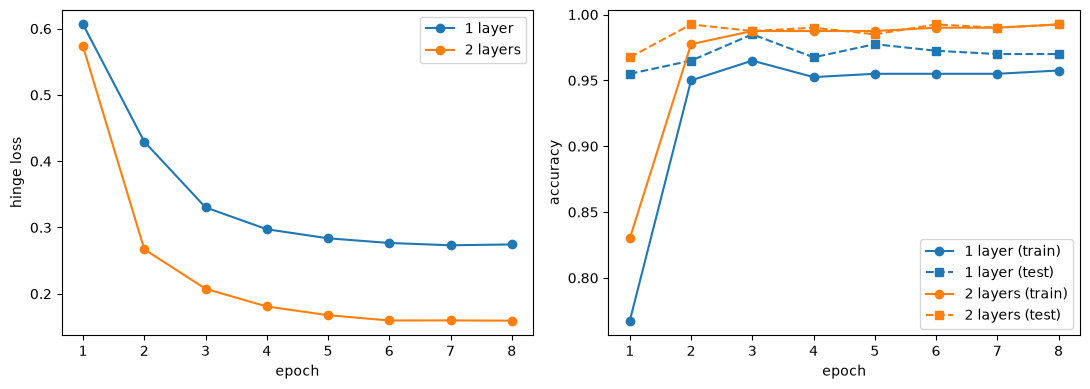

In [10]:
#| label: fig-mnist-training
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
epochs = np.arange(1, len(hist1["train_loss"]) + 1)
for hist, lab, col in [(hist1, "1 layer", "C0"), (hist2, "2 layers", "C1")]:
    axes[0].plot(epochs, hist["train_loss"], "o-", c=col, label=lab)
    axes[1].plot(epochs, hist["train_acc"], "o-", c=col, label=f"{lab} (train)")
    axes[1].plot(epochs, hist["test_acc"], "s--", c=col, label=f"{lab} (test)")
axes[0].set_ylabel("hinge loss"); axes[1].set_ylabel("accuracy")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout()
plt.show()

Both models learn quickly. The 1-layer circuit reaches about 97% test accuracy, and the deeper 2-layer circuit, with twice as many parameters, reaches about 99%. Always judge a model on the **test** set: images it has never seen during training.

````{admonition} Try this
:class: tip
1. (Exercise 6.2.1) Classify 3 vs 6 instead of 0 vs 1. Is it harder? Why might the central row be a poor choice for these digits?
2. How does the test accuracy depend on `N_TRAIN`?
3. Replace the parameter-shift gradient with SPSA (Lecture 5). It needs only 2 evaluations per image instead of $2P+1$. How does training change?
4. Add shot noise by setting `default_precision` to $1/\sqrt{\text{shots}}$. How many shots are needed to train well?
````